# Data Science 101 — Live Demo
### From Data to Model

Companion notebook for the presentation *"Data Science 101: From Data to Decisions"*.

**Part 1:** Regression — predicting restaurant tips
**Part 2:** Classification — predicting a breast cancer diagnosis

Both datasets are built into the libraries — no separate download needed.

In [1]:
%pip install pandas numpy seaborn matplotlib scikit-learn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.3.3-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 59.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 50.8 MB/s eta 0:00:0031m63.6 MB/s eta 0:00:01
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 33.5 MB/s eta 0:00:00MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 35.5 MB/s eta 0:00:00 MB/s eta 0:00:01
Using cached contourpy-1.3.3-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (363 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3

In [2]:
# Setup — all imports we need
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    classification_report,
)
from sklearn.datasets import load_breast_cancer

%matplotlib inline
sns.set_theme(style="whitegrid")

---
## Part 1: Predicting Tips (Regression)

**Target variable:** `tip` — what we want to predict
**Useful columns:** `total_bill`, `size`, `time`, `day`, `sex`, `smoker`

In [3]:
# Load the dataset — built directly into seaborn
# seaborn has several small example datasets taht are useful for learning data analysis and visualization. "tips" Is one of those example datasets.
tips = sns.load_dataset("tips") 

print(tips.shape)
print(tips.dtypes)
tips.head()

(244, 7)
total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


**Question for you:** Does `bill vs. tip` look linear? What do you notice about the spread?

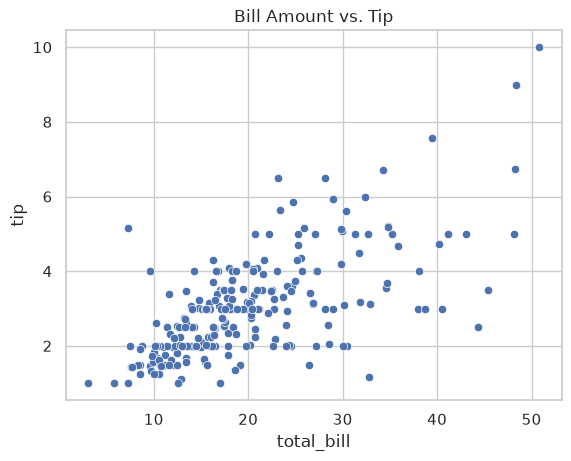

In [4]:
sns.scatterplot(data=tips, x="total_bill", y="tip")
plt.title("Bill Amount vs. Tip")
plt.show()

### Train a linear regression model

In [7]:
X = tips[["total_bill", "size"]]
y = tips["tip"]

# The training data is split into 20% test data and 80% training data
# This is what train_test_split method from sklearn.model.selection does for us
# The random_state of 42 is a fixed number to indicate which data is pulled for testing.
# As such the number 42 is of course a joke, referencing to the Hitchhiker's guide to the
# Galaxy
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Based on the scatter plot and the type of data we now choose the model LinearRegression. We could also have choosen Decision Trees, Random Forest, Gradient Boosting.
# Basically this is like a very limited baby of chatGPT, but only capable to learn LinearRegression. 
model = LinearRegression()
# Nice, we now have a model, but the model is not yet trained. It did not yet receive ANY training whatsoever. IT is empty.
# 
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"RMSE: ${rmse:.2f}  (on average we're about a dollar off)")
print(f"R²:   {r2:.2f}  (share of variance explained)")

RMSE: $0.81  (on average we're about a dollar off)
R²:   0.48  (share of variance explained)


**Question:** Not great — R² ~0.48. Can we do better? → Feature Engineering.

### Feature Engineering

Creating new columns from existing knowledge — we're not adding **any new data**,
we're just translating domain knowledge into model inputs.

- `is_dinner`: Dinner/Lunch turned into a numeric feature
- `bill_per_person`: total bill divided by table size

In [16]:
tips["is_dinner"] = (tips["time"] == "Dinner").astype(int)
tips["bill_per_person"] = tips["total_bill"] / tips["size"]

X2 = tips[["size", "is_dinner", "bill_per_person"]]
y2 = tips["tip"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

model2 = LinearRegression()
model2.fit(X2_train, y2_train)
y2_pred = model2.predict(X2_test)

rmse2 = np.sqrt(mean_squared_error(y2_test, y2_pred))
r2_2 = r2_score(y2_test, y2_pred)

print(f"Before — RMSE: ${rmse:.2f}, R²: {r2:.2f}")
print(f"After  — RMSE: ${rmse2:.2f}, R²: {r2_2:.2f}")

Before — RMSE: $0.81, R²: 0.48
After  — RMSE: $0.82, R²: 0.47


---
## Part 2: Detecting Cancer (Classification)

Same workflow, but a classification problem with much higher stakes.

- **569** real cases from tumor biopsies
- **30** features (measurements for each case)
- **Binary classification:** malignant or benign

**Note:** From here on we reuse `X`, `y`, `X_train`, `X_test`, `y_train`, `y_test`
— just like in Part 1. This is intentional, matches the code on the slide,
and simply overwrites the old tips variables, which we no longer need.

In [18]:
data = load_breast_cancer()

print("Target names:", data.target_names)
print("Shape:", data.data.shape)

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Target names: ['malignant' 'benign']
Shape: (569, 30)


### Baseline vs. Gradient Boosting

In [19]:
# Logistic Regression — simple, interpretable baseline
lr = LogisticRegression(max_iter=10000)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

# Gradient Boosting — stronger tree-based model
gbt = GradientBoostingClassifier(n_estimators=100, random_state=42)
gbt.fit(X_train, y_train)
gbt_pred = gbt.predict(X_test)

**Compare accuracy — but don't stop there.**

Accuracy alone can be misleading: two models can look almost equally good
even though one is noticeably worse on the more important class (malignant).
That's why we also look at F1 per class.

In [20]:
from sklearn.metrics import accuracy_score, f1_score

lr_acc = accuracy_score(y_test, lr_pred)
gbt_acc = accuracy_score(y_test, gbt_pred)

# pos_label=0 -> F1 for "malignant", the clinically more important class
lr_f1_malignant = f1_score(y_test, lr_pred, pos_label=0)
gbt_f1_malignant = f1_score(y_test, gbt_pred, pos_label=0)

# Default F1 (pos_label=1) -> "benign", for comparison
lr_f1_benign = f1_score(y_test, lr_pred)
gbt_f1_benign = f1_score(y_test, gbt_pred)

print(f"{'Model':<22}{'Accuracy':>10}{'F1 (malignant)':>16}{'F1 (benign)':>16}")
print(f"{'Logistic Regression':<22}{lr_acc:>10.3f}{lr_f1_malignant:>16.3f}{lr_f1_benign:>16.3f}")
print(f"{'Gradient Boosting':<22}{gbt_acc:>10.3f}{gbt_f1_malignant:>16.3f}{gbt_f1_benign:>16.3f}")

Model                   Accuracy  F1 (malignant)     F1 (benign)
Logistic Regression        0.965           0.951           0.973
Gradient Boosting          0.956           0.938           0.966


**Insight:** In this run, the simpler Logistic Regression wins on both metrics —
accuracy and F1 (malignant). This confirms what the slide's text claims but never
actually shows in code: more model complexity isn't automatically better, especially
on small, clean datasets like this one. Always run a baseline alongside and genuinely
compare — don't just assume the "stronger" model wins.

### Reading the Classification Report

| Metric | Meaning |
|---|---|
| Precision | Of everything predicted malignant: how many were correct? |
| Recall | Of everything actually malignant: how many did we catch? |
| F1 | Balance between precision and recall |
| Support | Number of real cases per class |

**Question for you:** In a medical context — which metric matters most? → *Recall for malignant.*

In [18]:
print("=== Logistic Regression ===")
print(classification_report(y_test, lr_pred, target_names=data.target_names))

print("=== Gradient Boosting ===")
print(classification_report(y_test, gbt_pred, target_names=data.target_names))

=== Logistic Regression ===
              precision    recall  f1-score   support

   malignant       0.97      0.93      0.95        42
      benign       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

=== Gradient Boosting ===
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



### Cross-Validation

A single train/test split can be lucky or unlucky. Cross-validation repeats
the experiment across multiple folds — similar scores across folds mean a
more stable model.

In [19]:
scores = cross_val_score(
    GradientBoostingClassifier(n_estimators=100, random_state=42),
    X, y, cv=5, scoring="accuracy"
)

print("Scores per fold:", np.round(scores, 3))
print(f"Mean: {scores.mean():.3f}  (Std: {scores.std():.3f})")

Scores per fold: [0.93  0.947 0.974 0.982 0.982]
Mean: 0.963  (Std: 0.021)


**What these numbers mean:**

The 5 fold scores range from roughly 0.93 to 0.98 — a spread of about 5 percentage
points, purely because of *which* rows ended up in the test set each time.

**This explains what we saw earlier:** when we compared GBT and Logistic Regression
on a single split, sometimes one model won, sometimes the other, depending on whether
`stratify=y` was used or not. That's exactly the "lucky or unlucky" effect of a single
split — the fold scores here show the same kind of swing, just systematically across
5 attempts instead of randomly across just 1.

**Rule of thumb:** A small standard deviation (here: 0.021) means the model is stable
across different slices of data. If the std were much larger (say, > 0.05), that would
be a warning sign of instability or too small a dataset.

---
## Mini-Challenge for You

**Challenge:**
1. Add `smoker`, `day`, or `sex` to the tips regression model.
   Encode categorical columns: `pd.get_dummies(tips, columns=["smoker"], drop_first=True)`
   Retrain and compare R² before/after.
2. Change `n_estimators` in the GBT model — does 50 trees behave differently than 200?
3. Run `cross_val_score` for Logistic Regression and compare its mean to GBT's.

Scaffolding for each task is further below — but try it yourselves first,
before looking.

In [ ]:
# Space for your solution — dive in!


---
### Scaffolding — in case you're not sure where to start

Three separate cells, one per task. Each has starter code; you fill in the rest.

**Task 1: Add `smoker` to the tips model and compare R²**

In [ ]:
# Task 1: encode a categorical column and retrain
tips_encoded = pd.get_dummies(tips, columns=["smoker"], drop_first=True)
print(tips_encoded.columns.tolist())  # check the new column(s)

# TODO: build X3 with the old features + the new smoker column
# X3 = tips_encoded[[..., "smoker_Yes"]]
# y3 = tips_encoded["tip"]
# X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.2, random_state=42)
# model3 = LinearRegression().fit(X3_train, y3_train)
# y3_pred = model3.predict(X3_test)
# r2_3 = r2_score(y3_test, y3_pred)
# print(f"R² before (without smoker): {r2:.3f}")
# print(f"R² after  (with smoker):    {r2_3:.3f}")

**Task 2: Change `n_estimators` in the GBT model — 50 vs. 200 trees**

In [20]:
# Task 2: compare GBT with different tree counts
for n in [50, 100, 200]:
    gbt_n = GradientBoostingClassifier(n_estimators=n, random_state=42)
    gbt_n.fit(X_train, y_train)
    acc_n = accuracy_score(y_test, gbt_n.predict(X_test))
    print(f"n_estimators={n:>3}: Accuracy = {acc_n:.3f}")

n_estimators= 50: Accuracy = 0.947
n_estimators=100: Accuracy = 0.956
n_estimators=200: Accuracy = 0.956


**Task 3: `cross_val_score` for Logistic Regression, compare its mean to GBT's**

In [21]:
# Task 3: cross-validation for Logistic Regression
lr_scores = cross_val_score(
    LogisticRegression(max_iter=10000),
    X, y, cv=5, scoring="accuracy"
)

print(f"Logistic Regression — Mean: {lr_scores.mean():.3f}  (Std: {lr_scores.std():.3f})")
print(f"Gradient Boosting   — Mean: {scores.mean():.3f}  (Std: {scores.std():.3f})")

Logistic Regression — Mean: 0.951  (Std: 0.018)
Gradient Boosting   — Mean: 0.963  (Std: 0.021)


**Bonus goal:** Change one thing, rerun the workflow, and explain what happened.

---
## Q&A

What would you predict next?